# Handwritten Digit Classification with the SVD

Classifying handwritten digits (US Postal Service data, 16×16 grayscale images) using one SVD basis per digit class. A test digit is assigned to the class whose subspace represents it best, measured by the relative residual of its projection onto the first $k$ left singular vectors.

The notebook covers:
1. **Choosing k:** accuracy as a function of the number of basis vectors
2. **Per-class difficulty:** which digits are hardest to classify, with examples of misclassified digits
3. **Per-class k:** whether a different number of basis vectors per class helps, based on the singular values
4. **Two-stage algorithm:** classifying with a single singular vector first, and running the full algorithm only when that is inconclusive

**Data:** a subset of the USPS digit database (1707 training and 2007 test images), from Lars Eldén's *Matrix Methods in Data Mining and Pattern Recognition* course material. Download `azip.mat`, `dzip.mat`, `testzip.mat` and `dtest.mat` from [this page](https://users.mai.liu.se/larel04/matrix-methods/computer-assignments/character-recogn.html) and put them in the same folder as the notebook.

## Loading the data

Each column of `A_train` / `A_test` is one 16×16 image stored as a 256-dimensional vector. `d_train` / `d_test` hold the true labels.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd
from scipy.io import loadmat
import warnings
warnings.filterwarnings('ignore')

# the four .mat files must be in the same folder as the notebook
A_train = loadmat('azip.mat')['azip'].astype(float)
d_train = loadmat('dzip.mat')['dzip'].flatten().astype(int)
A_test  = loadmat('testzip.mat')['testzip'].astype(float)
d_test  = loadmat('dtest.mat')['dtest'].flatten().astype(int)

print(f"Training images: {A_train.shape} | Test images: {A_test.shape}")
for d in range(10):
    print(f"  Digit {d}: {(d_train==d).sum():3d} train  |  {(d_test==d).sum():3d} test")

Training images: (256, 1707) | Test images: (256, 2007)
  Digit 0: 319 train  |  359 test
  Digit 1: 252 train  |  264 test
  Digit 2: 202 train  |  198 test
  Digit 3: 131 train  |  166 test
  Digit 4: 122 train  |  200 test
  Digit 5:  88 train  |  160 test
  Digit 6: 151 train  |  170 test
  Digit 7: 166 train  |  147 test
  Digit 8: 144 train  |  166 test
  Digit 9: 132 train  |  177 test


## Displaying digits

`ima2` reshapes a 256-vector into a 16×16 image and displays it (a Python port of the course's MATLAB function `ima2.m`).

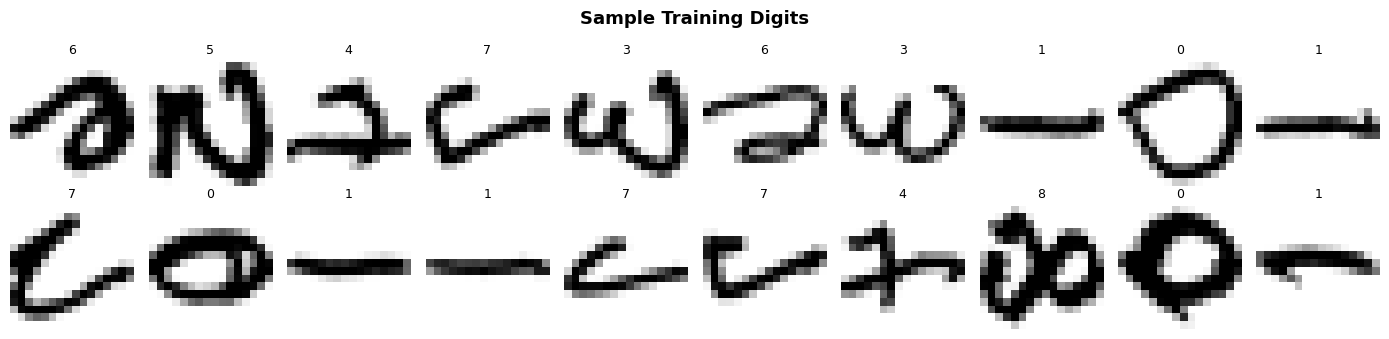

In [5]:
def ima2(vec, ax=None, title=''):
    img = vec.flatten().reshape(16, 16).T
    img = img - img.min()
    if img.max() > 0:
        img = (img / img.max()) * 20
    if ax is None:
        fig, ax = plt.subplots()
    ax.imshow(img, cmap='gray_r', interpolation='nearest')
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=9)

# show 20 sample training digits
fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))
for i, ax in enumerate(axes.flatten()):
    ima2(A_train[:, i], ax=ax, title=str(d_train[i]))
fig.suptitle('Sample Training Digits', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## SVD of each digit class

For each digit, the training images of that class form a 256 × $n_d$ matrix. Its left singular vectors $U$ give an orthonormal basis for the class, ordered by importance.

In [7]:
def build_svd_bases(A_train, d_train):
    bases = {}
    for digit in range(10):
        idx = np.where(d_train == digit)[0]
        X = A_train[:, idx]
        U, s, Vt = svd(X, full_matrices=False)
        bases[digit] = (U, s)
    return bases

bases = build_svd_bases(A_train, d_train)


## Singular values per class

The normalised singular values $\sigma_i/\sigma_1$ of each class, and the smallest $k$ that captures 90% of the class's energy $\sum \sigma_i^2$.

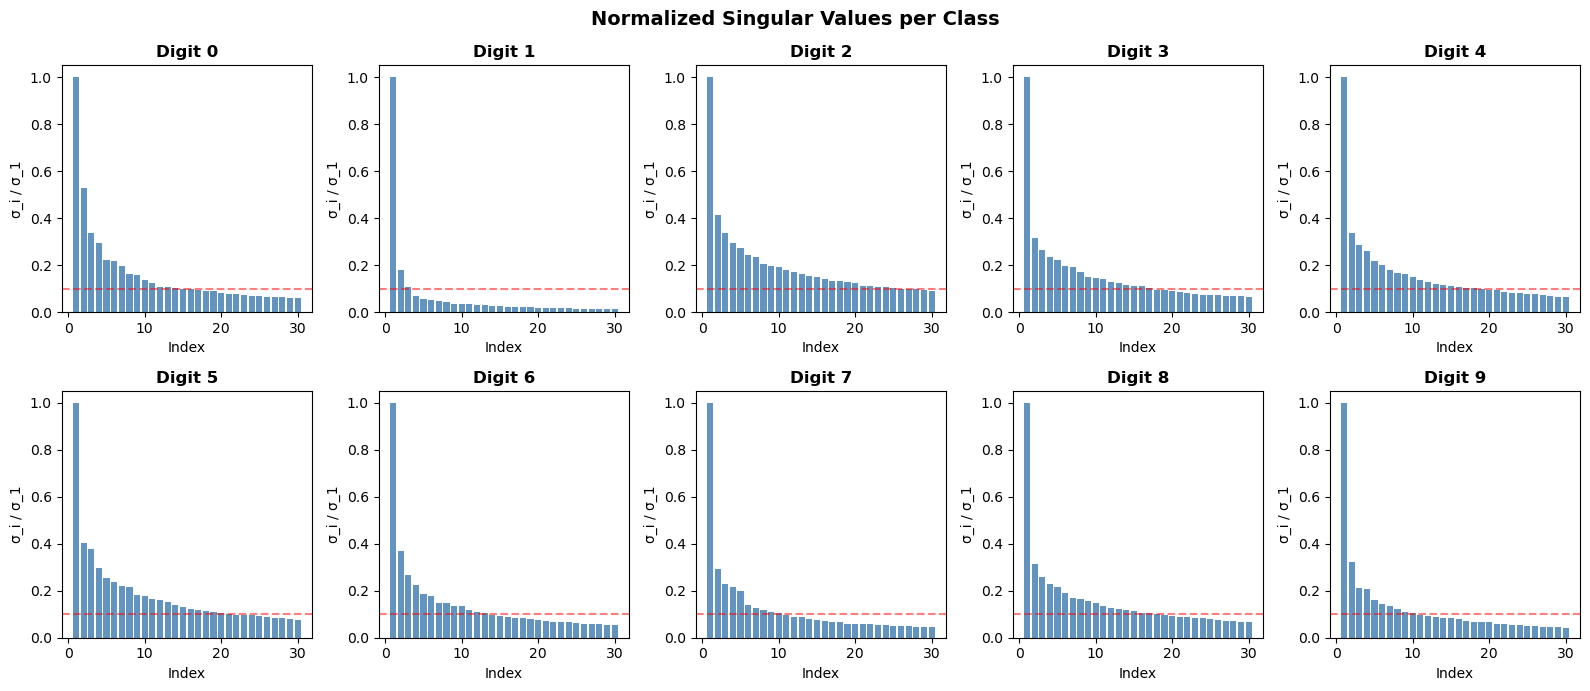


Minimum k to get 90%:
  Digit 0: k=15  (90.4%)
  Digit 1: k= 1  (93.2%)
  Digit 2: k=28  (90.4%)
  Digit 3: k=18  (90.4%)
  Digit 4: k=17  (90.0%)
  Digit 5: k=19  (90.2%)
  Digit 6: k=12  (90.2%)
  Digit 7: k= 9  (90.7%)
  Digit 8: k=19  (90.2%)
  Digit 9: k= 9  (90.5%)


In [9]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for digit, ax in enumerate(axes.flatten()):
    U, s = bases[digit]
    sv_norm = s[:30] / s[0]
    ax.bar(range(1, 31), sv_norm, color='steelblue', alpha=0.85)
    ax.set_title(f'Digit {digit}', fontweight='bold')
    ax.set_xlabel('Index'); ax.set_ylabel('σ_i / σ_1')
    ax.set_ylim(0, 1.05)
    ax.axhline(0.1, color='red', ls='--', alpha=0.5)

fig.suptitle('Normalized Singular Values per Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# smallest k that captures 90% of the energy
print("\nMinimum k to get 90%:")
recommended_k = {}
for digit in range(10):
    U, s = bases[digit]
    energy = np.cumsum(s**2) / np.sum(s**2)
    k90 = np.searchsorted(energy, 0.90) + 1
    recommended_k[digit] = k90
    print(f"  Digit {digit}: k={k90:2d}  ({energy[k90-1]*100:.1f}%)")

## Classification algorithm

For a test digit $x$ and each class $d$, project $x$ onto the first $k$ basis vectors $U_k$ and compute the relative residual

$$r_d = \frac{\|x - U_k U_k^T x\|_2}{\|x\|_2}.$$

The digit is assigned to the class with the smallest residual.

True label: 9  |  Predicted: 9
Residuals per class: [0.691  0.768  0.7475 0.6733 0.5274 0.7191 0.7813 0.5556 0.6755 0.3072]


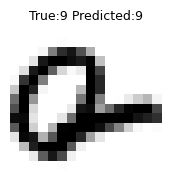

In [11]:
def classify_digit(x, bases, k):
    x = x.flatten()
    norm_x = np.linalg.norm(x)
    residuals = np.zeros(10)
    for digit in range(10):
        U, s = bases[digit]
        Uk = U[:, :k]
        proj = Uk @ (Uk.T @ x)
        residuals[digit] = np.linalg.norm(x - proj) / (norm_x + 1e-12)
    return np.argmin(residuals), residuals

# example: classify one test digit
x_demo = A_test[:, 0]
pred, res = classify_digit(x_demo, bases, k=10)
print(f"True label: {d_test[0]}  |  Predicted: {pred}")
print("Residuals per class:", np.round(res, 4))

fig, ax = plt.subplots(1, 1, figsize=(2, 2))
ima2(x_demo, ax=ax, title=f'True:{d_test[0]} Predicted:{pred}')
plt.tight_layout(); plt.show()

## 1. Choosing k

Accuracy on the whole test set for $k = 1, \dots, 20$ basis vectors.

In [13]:
k_range = range(1, 21)
accuracies = []

for k in k_range:
    correct = sum(
        1 for i in range(A_test.shape[1])
        if classify_digit(A_test[:, i], bases, k)[0] == d_test[i]
    )
    acc = correct / A_test.shape[1] * 100
    accuracies.append(acc)
    print(f"k={k:2d} : accuracy = {acc:.2f}%")

best_k = list(k_range)[np.argmax(accuracies)]
best_acc = max(accuracies)
print(f"\nBest: k={best_k} : {best_acc:.2f}%")


k= 1 : accuracy = 80.17%
k= 2 : accuracy = 86.30%
k= 3 : accuracy = 87.89%
k= 4 : accuracy = 89.99%
k= 5 : accuracy = 90.28%
k= 6 : accuracy = 90.53%
k= 7 : accuracy = 91.68%
k= 8 : accuracy = 92.03%
k= 9 : accuracy = 92.63%
k=10 : accuracy = 93.17%
k=11 : accuracy = 93.22%
k=12 : accuracy = 93.57%
k=13 : accuracy = 93.62%
k=14 : accuracy = 93.92%
k=15 : accuracy = 94.12%
k=16 : accuracy = 93.87%
k=17 : accuracy = 93.92%
k=18 : accuracy = 94.17%
k=19 : accuracy = 94.07%
k=20 : accuracy = 93.97%

Best: k=18 : 94.17%


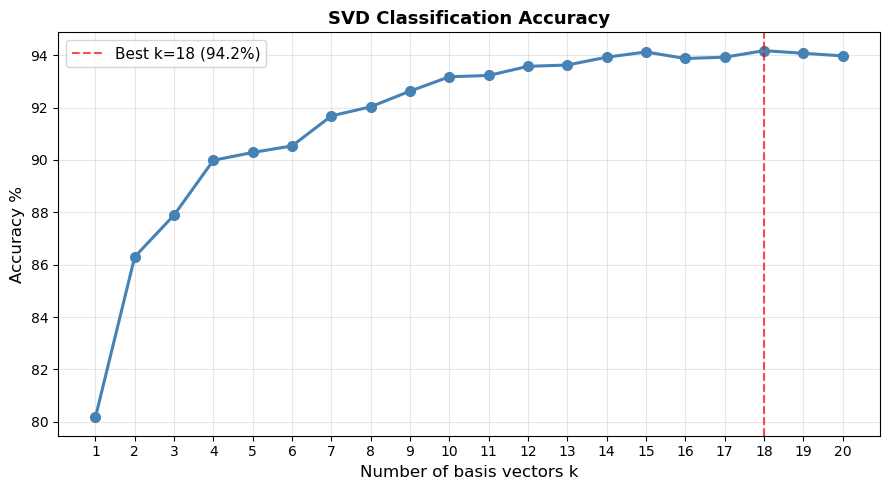

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(list(k_range), accuracies, 'o-', color='steelblue', lw=2.2, ms=7)
ax.axvline(best_k, color='red', ls='--', alpha=0.7, label=f'Best k={best_k} ({best_acc:.1f}%)')
ax.set_xlabel('Number of basis vectors k', fontsize=12)
ax.set_ylabel('Accuracy %', fontsize=12)
ax.set_title('SVD Classification Accuracy', fontsize=13, fontweight='bold')
ax.legend(fontsize=11); ax.grid(True, alpha=0.3)
ax.set_xticks(list(k_range))
plt.tight_layout(); plt.show()


## 2. Are all digits equally hard?

Accuracy per digit class at the best $k$, ranked from hardest to easiest.

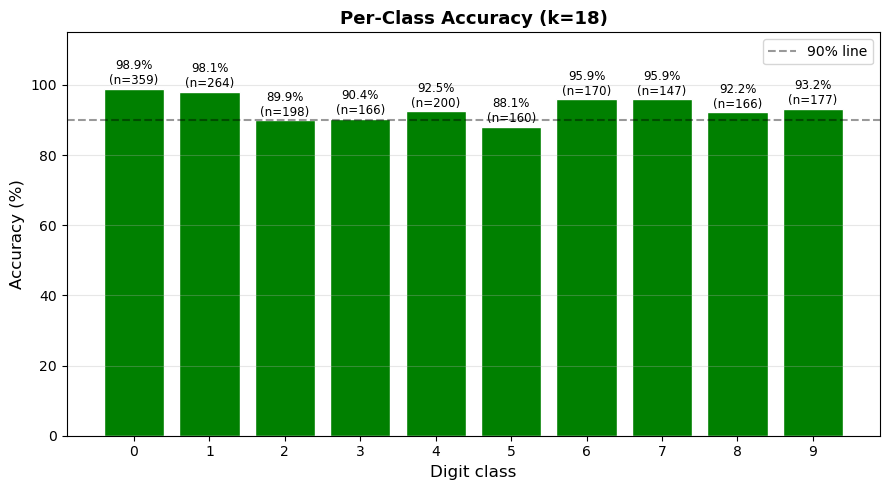


Digits ranked by difficulty:
  Digit 5: 88.12%
  Digit 2: 89.90%
  Digit 3: 90.36%
  Digit 8: 92.17%
  Digit 4: 92.50%
  Digit 9: 93.22%
  Digit 6: 95.88%
  Digit 7: 95.92%
  Digit 1: 98.11%
  Digit 0: 98.89%


In [16]:
def per_class_accuracy(bases, A_test, d_test, k):
    class_correct = np.zeros(10)
    class_total   = np.zeros(10)
    misclassified = {d: [] for d in range(10)}
    for i in range(A_test.shape[1]):
        true_label = d_test[i]
        pred, residuals = classify_digit(A_test[:, i], bases, k)
        class_total[true_label] += 1
        if pred == true_label:
            class_correct[true_label] += 1
        else:
            misclassified[true_label].append((i, pred))
    return class_correct / (class_total + 1e-12) * 100, misclassified, class_total

class_acc, misclassified, class_total = per_class_accuracy(bases, A_test, d_test, k=best_k)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(range(10), class_acc, color='green', edgecolor='white')
for bar, acc, tot in zip(bars, class_acc, class_total):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{acc:.1f}%\n(n={int(tot)})', ha='center', va='bottom', fontsize=8.5)
ax.set_xlabel('Digit class', fontsize=12); ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title(f'Per-Class Accuracy (k={best_k})', fontsize=13, fontweight='bold')
ax.set_ylim(0, 115); ax.set_xticks(range(10))
ax.axhline(90, color='black', ls='--', alpha=0.4, label='90% line')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

print("\nDigits ranked by difficulty:")
order = np.argsort(class_acc)
for d in order:
    print(f"  Digit {d}: {class_acc[d]:.2f}%")


### Examples of misclassified digits

The first 5 misclassified test images of each class. Many of them are badly written.

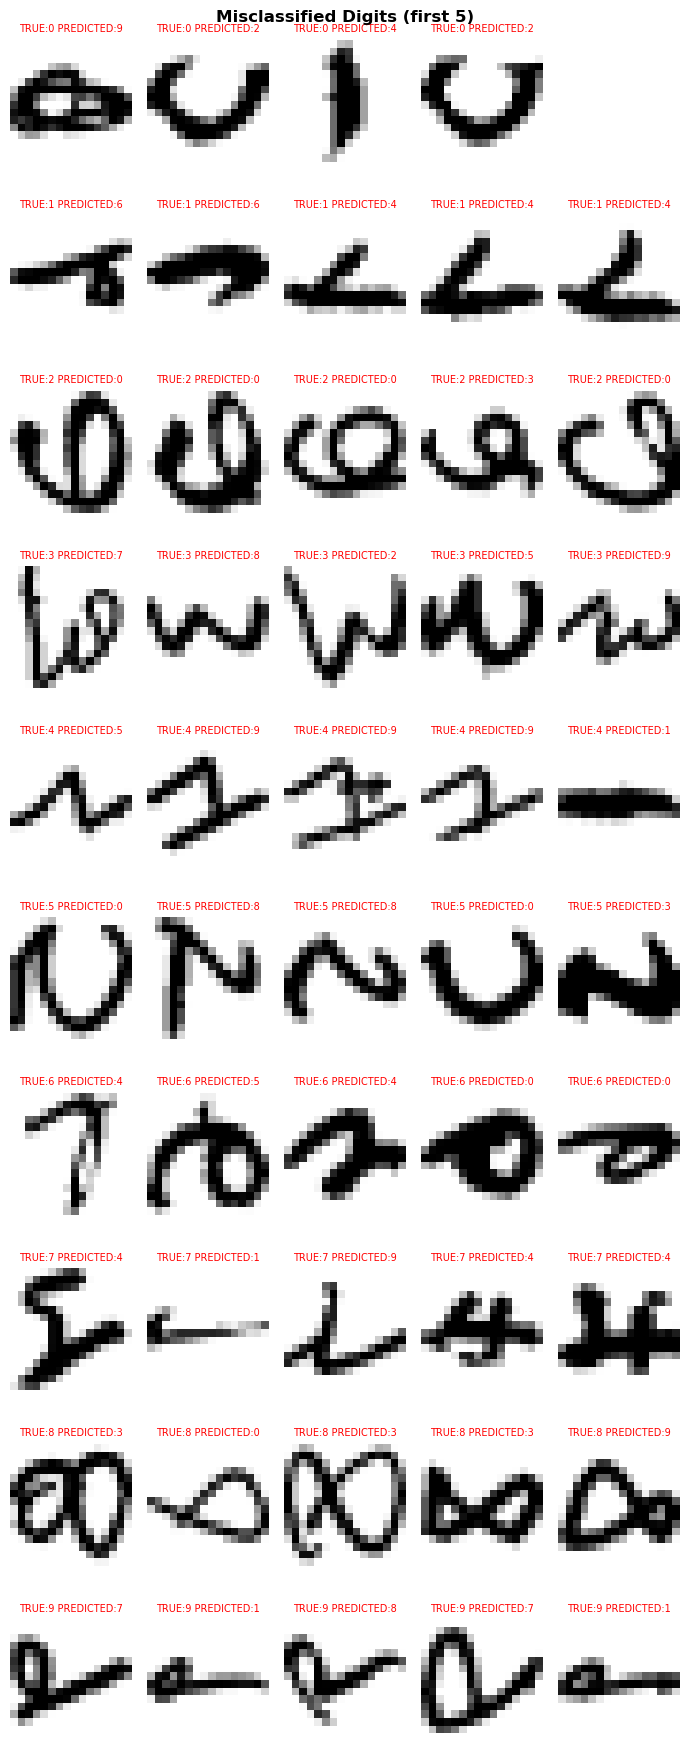

In [18]:
fig, axes = plt.subplots(10, 5, figsize=(7, 18))
for digit in range(10):
    examples = misclassified[digit][:5]
    for j in range(5):
        ax = axes[digit][j]
        if j < len(examples):
            idx, pred = examples[j]
            ima2(A_test[:, idx], ax=ax)
            ax.set_title(f'TRUE:{digit} PREDICTED:{pred}', fontsize=7, color='red')
        else:
            ax.axis('off')
fig.suptitle('Misclassified Digits (first 5)', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()


## 3. A different k per class

The singular values decay at different rates for different digits (digit 1 needs only $k=1$ for 90% of its energy, digit 2 needs $k=28$). Here each class uses its own 90%-energy $k$ from above, compared with a single $k$ for all classes.

In [20]:
def classify_adaptive(x, bases, k_per_class):
    x = x.flatten()
    norm_x = np.linalg.norm(x)
    residuals = np.zeros(10)
    for digit in range(10):
        U, s = bases[digit]
        Uk = U[:, :k_per_class[digit]]
        proj = Uk @ (Uk.T @ x)
        residuals[digit] = np.linalg.norm(x - proj) / (norm_x + 1e-12)
    return np.argmin(residuals), residuals

adaptive_acc = sum(
    1 for i in range(A_test.shape[1])
    if classify_adaptive(A_test[:, i], bases, recommended_k)[0] == d_test[i]
) / A_test.shape[1] * 100

print(f"Adaptive k per class: { {d: int(k) for d, k in recommended_k.items()} }")
print(f"Adaptive accuracy: {adaptive_acc:.2f}%")
print(f"k={best_k}: {best_acc:.2f}%")

Adaptive k per class: {0: 15, 1: 1, 2: 28, 3: 18, 4: 17, 5: 19, 6: 12, 7: 9, 8: 19, 9: 9}
Adaptive accuracy: 90.88%
k=18: 94.17%


**So choosing k per class by the 90%-energy rule does not improve accuracy.**

## 4. Two-stage algorithm

**Stage 1:** compare the test digit only with the first singular vector of each class. If the smallest residual is clearly smaller than the second smallest (their ratio is below a threshold θ), assign the digit to that class.

**Stage 2:** otherwise, run the full algorithm with the best $k$.

The table shows the accuracy for different θ and how often stage 2 is needed.

In [23]:
def classify_two_stage(x, bases, k_full, theta=0.7):
    x = x.flatten()
    norm_x = np.linalg.norm(x)
    res1 = np.array([
        np.linalg.norm(x - U[:,:1] @ (U[:,:1].T @ x)) / (norm_x + 1e-12)
        for _, (U, s) in sorted(bases.items())
    ])
    sorted_res = np.sort(res1)
    if sorted_res[0] / sorted_res[1] < theta:
        return np.argmin(res1), False   # Stage 1
    # Stage 2
    residuals = np.array([
        np.linalg.norm(x - U[:,:k_full] @ (U[:,:k_full].T @ x)) / (norm_x + 1e-12)
        for _, (U, s) in sorted(bases.items())
    ])
    return np.argmin(residuals), True

print(f"{'theta':>6} | {'accuracy':>10} | {'stage-2 rate':>13}")
print("-"*36)
for theta in [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9]:
    correct = 0; s2_used = 0
    for i in range(A_test.shape[1]):
        pred, used_s2 = classify_two_stage(A_test[:, i], bases, k_full=best_k, theta=theta)
        if pred == d_test[i]: correct += 1
        if used_s2: s2_used += 1
    acc = correct / A_test.shape[1] * 100
    s2_pct = s2_used / A_test.shape[1] * 100
    print(f"{theta:>6.2f} | {acc:>9.2f}% | {s2_pct:>12.1f}%")


 theta |   accuracy |  stage-2 rate
------------------------------------
  0.50 |     94.17% |         90.0%
  0.60 |     94.17% |         87.5%
  0.70 |     94.17% |         79.5%
  0.75 |     94.17% |         72.3%
  0.80 |     94.12% |         63.9%
  0.85 |     93.82% |         52.2%
  0.90 |     92.97% |         38.7%
